# Modul 2 - Missing Data & Data Quality

**Project:** Practical EDA with Python  
**Level:** Intermediate  
**Tools:** Python, Pandas, Matplotlib  
**Output:** Missing Data Report dan Missing Data Chart

## Project Challenge

Pada Modul 1 kita sudah mengenal struktur dataset. Sekarang kita perlu menjawab pertanyaan penting: **apakah data yang kita miliki sudah lengkap?**

Missing value dapat membuat hasil analisis bias atau menyesatkan. Pada modul ini kita akan melakukan data quality check, mengukur missing data, memilih treatment, dan mendokumentasikan keputusan cleaning.

## Tujuan Pembelajaran

Setelah menyelesaikan notebook ini, kamu mampu:

- menemukan missing value menggunakan Pandas;
- menghitung jumlah dan persentase missing value;
- membedakan missing value dengan nilai `0`;
- memilih strategi `dropna()` atau `fillna()` berdasarkan konteks;
- memvisualisasikan missing data;
- membandingkan kondisi data sebelum dan sesudah treatment.

## Project Workflow

`Dataset -> Data Quality Check -> Missing Data -> Treatment -> Before vs After -> Missing Data Report`

## 1. Persiapan Project

Kita menggunakan dataset yang sama dengan Modul 1. Pastikan setiap baris tetap merepresentasikan satu transaksi.

In [9]:
nilai_mtk = 100
print(f"nilai matematika adalah {nilai_mtk}")


nilai matematika adalah 100


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

df = pd.read_csv('data/sales_eda_sample.csv')

print("jumlah baris adalah", df.shape[0], "baris")

print(f"jumlah kolom adalah {df.shape[1]} kolom" )

# print(f'Ukuran dataset: {df.shape[0]} baris dan {df.shape[1]} kolom')
# df.head()

jumlah baris adalah 123 baris
jumlah kolom adalah 8 kolom


In [ ]:
# melihat nama kolom, jumlah data yang tidak kosong, dan tipe data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  123 non-null    str    
 1   date      123 non-null    str    
 2   product   123 non-null    str    
 3   category  123 non-null    str    
 4   city      118 non-null    str    
 5   quantity  119 non-null    float64
 6   price     121 non-null    float64
 7   revenue   121 non-null    float64
dtypes: float64(3), str(5)
memory usage: 12.8 KB


## 2. Apa Itu Missing Data?

Missing data adalah kondisi ketika sebuah nilai tidak tersedia. Dalam Pandas, kondisi ini umumnya direpresentasikan sebagai `NaN`.

Nilai missing berbeda dengan angka `0`. Angka `0` adalah nilai yang tercatat, sedangkan `NaN` berarti informasi belum tersedia.

## 3. Missing Data Check

`isna()` menghasilkan `True` untuk nilai yang missing dan `False` untuk nilai yang tersedia.

In [14]:
missing_flags = df.isna()
missing_flags.head(20)

,order_id,date,product,category,city,quantity,price,revenue
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
5,False,False,False,False,False,False,False,False
6,False,False,False,False,False,False,False,False
7,False,False,False,False,True,False,False,False
8,False,False,False,False,False,False,False,False
9,False,False,False,False,False,False,False,False


In [ ]:
missing_count = df.isna().sum() # jumlahkan semua nilai kosong (True) di setiap kolom
missing_count

order_id    0
date        0
product     0
category    0
city        5
quantity    4
price       2
revenue     2
dtype: int64

Gunakan hasil di atas untuk menjawab:

1. Kolom mana yang paling banyak missing?
2. Kolom mana yang tidak memiliki missing?
3. Apakah semua missing value harus dihapus?

## 4. Missing Data Summary

Jumlah missing saja belum cukup. Persentase membantu kita memahami seberapa besar masalah dibandingkan jumlah seluruh baris.

In [18]:
missing_report = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': df.isna().mean() * 100
})

missing_report = missing_report.sort_values('missing_count', ascending=False)
missing_report.style.format({'missing_percent': '{:.2f}%'})

,missing_count,missing_percent
city,5,4.07%
quantity,4,3.25%
revenue,2,1.63%
price,2,1.63%
category,0,0.00%
product,0,0.00%
date,0,0.00%
order_id,0,0.00%


## 5. Missing Data Visualization

Grafik berikut hanya menampilkan kolom yang memiliki missing value. Jika tidak ada kolom missing, pesan informatif akan ditampilkan.

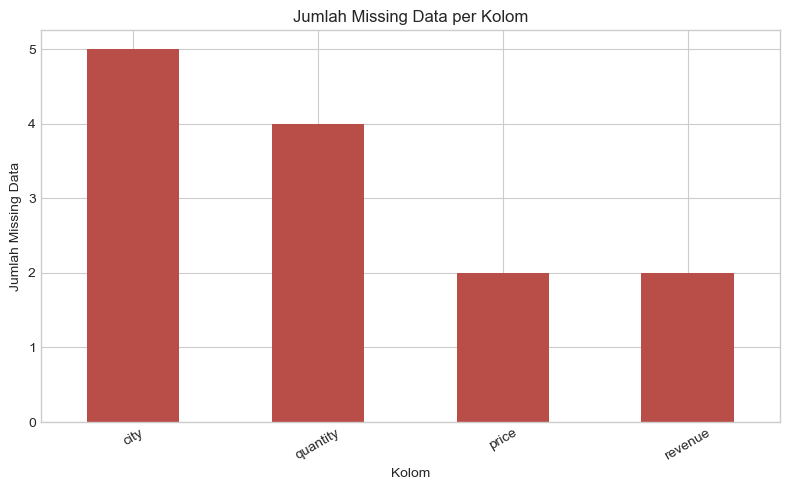

In [19]:
missing_only = missing_count[missing_count > 0]

if missing_only.empty:
    print('Tidak ditemukan missing value pada dataset.')
else:
    missing_only.plot(kind='bar', figsize=(8, 5), color='#b94e48')
    plt.title('Jumlah Missing Data per Kolom')
    plt.xlabel('Kolom')
    plt.ylabel('Jumlah Missing Data')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

## 6. Menentukan Strategi Treatment

Missing value adalah masalah data, bukan sekadar masalah kode. Sebelum memilih treatment, pahami arti kolom dan sumber datanya.

Strategi umum:

- `dropna()`: digunakan jika jumlah missing kecil dan baris tersebut dapat dihilangkan.
- `fillna('Unknown')`: cocok untuk kategori yang informasinya perlu dipertahankan.
- `fillna(median)`: dapat digunakan untuk numerik ketika median mewakili data lebih baik daripada mean.
- Rekonstruksi dari kolom lain: dipertimbangkan jika nilai dapat dihitung secara logis, misalnya `revenue = quantity * price`.

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  123 non-null    str    
 1   date      123 non-null    str    
 2   product   123 non-null    str    
 3   category  123 non-null    str    
 4   city      118 non-null    str    
 5   quantity  119 non-null    float64
 6   price     121 non-null    float64
 7   revenue   121 non-null    float64
dtypes: float64(3), str(5)
memory usage: 12.8 KB


In [21]:
df_dropped = df.dropna()
df_dropped.info()

<class 'pandas.DataFrame'>
Index: 110 entries, 0 to 122
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  110 non-null    str    
 1   date      110 non-null    str    
 2   product   110 non-null    str    
 3   category  110 non-null    str    
 4   city      110 non-null    str    
 5   quantity  110 non-null    float64
 6   price     110 non-null    float64
 7   revenue   110 non-null    float64
dtypes: float64(3), str(5)
memory usage: 12.3 KB


## 7. Guided Exercise - Memperbaiki Dataset

Untuk latihan ini, kita mempertahankan semua transaksi. Kolom kategorikal `city` diisi dengan `Unknown`, sedangkan kolom numerik `quantity` diisi dengan median. Treatment dilakukan pada salinan dataset agar data mentah tetap tersedia.

In [ ]:
before = df.isna().sum().copy()
df_clean = df.copy()

if 'city' in df_clean.columns:
    df_clean['city'] = df_clean['city'].fillna('Unknown')

if 'quantity' in df_clean.columns:
    quantity_median = df_clean['quantity'].median()
    df_clean['quantity'] = df_clean['quantity'].fillna(quantity_median)

after = df_clean.isna().sum().copy()

print('Missing value sebelum treatment:')
print(before)
print('\nMissing value setelah treatment:')
print(after)

### Catatan Treatment

Keputusan di atas adalah contoh untuk latihan, bukan aturan universal. Jika kolom lain masih memiliki missing value, keputusan treatment harus dibuat setelah memahami sumber dan makna kolom tersebut.

## 8. Before vs After

Bandingkan jumlah missing sebelum dan sesudah treatment sebagai bukti perubahan kualitas data.

In [ ]:
comparison = pd.DataFrame({
    'Before': before,
    'After': after
})

comparison_to_plot = comparison[comparison['Before'] > 0]
comparison_to_plot

In [ ]:
if comparison_to_plot.empty:
    print('Tidak ada missing value untuk dibandingkan.')
else:
    comparison_to_plot.plot(kind='bar', figsize=(9, 5), color=['#b94e48', '#4c8c6b'])
    plt.title('Perbandingan Missing Data Before vs After')
    plt.xlabel('Kolom')
    plt.ylabel('Jumlah Missing Data')
    plt.xticks(rotation=30)
    plt.legend(title='Kondisi')
    plt.tight_layout()
    plt.show()

## 9. Data Analyst Findings

Tulis analisis berdasarkan `missing_report` dan grafik yang dihasilkan. Gunakan format berikut:

**Kolom:** ...  
**Jumlah missing:** ...  
**Persentase:** ...  
**Treatment:** ...  
**Alasan:** ...

### Data Analyst Challenge

Jika kolom `revenue` memiliki 10% missing value, apakah kamu akan langsung mengisinya dengan mean? Pertimbangkan terlebih dahulu:

- dari mana nilai `revenue` berasal;
- apakah `revenue` dapat dihitung dari kolom lain;
- apakah nilai yang hilang dapat direkonstruksi;
- apakah mean sesuai dengan karakteristik data.

## Deliverables dan Checklist

Notebook ini menghasilkan:

- Missing Data Report berisi nama kolom, jumlah missing, persentase, treatment, dan alasan;
- Missing Data Chart;
- Before vs After Chart.

### Checklist

- [ ] Mampu menggunakan `isna()`
- [ ] Mampu menghitung missing dengan `sum()`
- [ ] Mampu menghitung persentase missing
- [ ] Membuat Missing Data Report
- [ ] Membuat Missing Data Chart
- [ ] Memahami `dropna()` dan `fillna()`
- [ ] Memilih treatment berdasarkan konteks
- [ ] Membuat Before vs After Chart
- [ ] Menulis alasan treatment

## Progress Project

`RAW DATASET -> DATASET OVERVIEW -> DATA QUALITY CHECK -> MISSING DATA -> TREATMENT -> MISSING DATA REPORT`

## Next: Modul 3

Pada modul berikutnya kita akan menangani data yang tidak kosong, tetapi format dan nilainya tidak konsisten: **Data Cleaning & Transformation**.